# Case Study: Online Retail Transaction Clustering

## 1. Introduction
This case study analyzes online retail transactions to identify purchasing patterns and group similar shopping baskets. Python libraries such as Pandas, NumPy, Matplotlib, and Scikit-learn are used for data cleaning, statistical analysis, visualization, dimensionality reduction, and clustering.

## 2. Objectives
- Understand and clean the retail transaction dataset.
- Calculate transaction statistics and identify frequently purchased products.
- Visualize product frequencies and transaction sizes.
- Convert shopping baskets into numerical features.
- Apply Principal Component Analysis (PCA).
- Compare K-means, Hierarchical Clustering, Spectral Clustering, and DBSCAN.
- Evaluate clustering performance using suitable metrics.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 3. Loading the Dataset

The retail dataset is loaded into a Pandas DataFrame. Each row represents a shopping transaction, and the columns contain products purchased in that transaction. A sample of the records is displayed to understand the dataset structure.

In [2]:
df = pd.read_csv("Online retail_new.csv", header=None)
df.sample(5)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
5708,oil,escalope,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4725,cookies,green tea,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7315,spaghetti,chocolate,olive oil,fromage blanc,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
429,tomatoes,mineral water,soup,mashed potato,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
84,energy bar,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Understanding the Dataset

The first and last records are examined to understand the data. The shape of the DataFrame is checked to determine the number of transactions and product columns available for analysis.

In [3]:
df.head(10)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
0,shrimp,almonds,avocado,vegetables mix,green grapes,whole weat flour,yams,cottage cheese,energy drink,tomato juice,low fat yogurt,green tea,honey,salad,mineral water,salmon,antioxydant juice,frozen smoothie,spinach,olive oil
1,burgers,meatballs,eggs,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,chutney,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,turkey,avocado,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,mineral water,milk,energy bar,whole wheat rice,green tea,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,low fat yogurt,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,whole wheat pasta,french fries,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,soup,light cream,shallot,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,frozen vegetables,spaghetti,green tea,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,french fries,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
df.tail(10)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
7491,herb & pepper,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7492,chocolate,escalope,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7493,burgers,salmon,pancakes,french fries,frozen smoothie,fresh bread,mint,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7494,turkey,burgers,dessert wine,shrimp,pasta,tomatoes,pepper,milk,pancakes,whole wheat rice,oil,frozen smoothie,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7495,pancakes,light mayo,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7496,butter,light mayo,fresh bread,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7497,burgers,frozen vegetables,eggs,french fries,magazines,green tea,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7498,chicken,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7499,escalope,green tea,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7500,eggs,frozen smoothie,yogurt cake,low fat yogurt,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
df.shape

(7501, 20)

## 5. Data Cleaning and Preprocessing

Extra spaces are removed from product names, and empty strings are replaced with missing values. Missing values and duplicate transactions are examined. Completely empty rows are removed because they do not contain useful transaction information. Duplicate rows are checked and interpreted carefully because identical baskets may represent repeated purchases.

In [6]:
for column in df.columns:
    df[column] = df[column].str.strip()

In [7]:
df.sample(10)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
5279,frozen vegetables,mineral water,french fries,mushroom cream sauce,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5433,turkey,pepper,carrots,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1990,spaghetti,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6907,milk,eggs,burger sauce,cooking oil,sandwich,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1726,chocolate,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3567,vegetables mix,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2241,burgers,shrimp,mineral water,milk,energy bar,rice,brownies,yogurt cake,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6119,chocolate,ground beef,soup,energy drink,low fat yogurt,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5325,mineral water,french fries,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1184,protein bar,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
df = df.replace("", pd.NA)

In [9]:
df.sample(5)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
6502,parmesan cheese,french wine,cooking oil,low fat yogurt,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5219,burgers,red wine,mineral water,avocado,eggs,yogurt cake,protein bar,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6507,oil,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2235,cookies,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2066,frozen vegetables,chocolate,whole wheat rice,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
# Check missing values
print("Missing values:\n",df.isnull().sum().sum())

# Check duplicate transactions
print("Duplicate rows:", df.duplicated().sum())

Missing values:
 120657
Duplicate rows: 2325


In [11]:


# Remove completely empty rows
df = df.dropna(how="all")

# Check missing values and duplicates
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

# Display cleaned data
display(df.head())


Missing values: 120657
Duplicate rows: 2325


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
0,shrimp,almonds,avocado,vegetables mix,green grapes,whole weat flour,yams,cottage cheese,energy drink,tomato juice,low fat yogurt,green tea,honey,salad,mineral water,salmon,antioxydant juice,frozen smoothie,spinach,olive oil
1,burgers,meatballs,eggs,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,chutney,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,turkey,avocado,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,mineral water,milk,energy bar,whole wheat rice,green tea,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 6. Statistical Analysis

Descriptive statistics are calculated to understand the number of products in each transaction. The mean, median, standard deviation, minimum, and maximum transaction sizes are examined. Product frequencies are also calculated to identify the most frequently occurring items.

In [12]:

# Transaction statistics
print("Total transactions:", len(df))

# Products in each transaction
print("\nTransaction size statistics:")
k=df.count(axis=1)
print(k.describe())

# Top 10 frequently purchased products
print("\nTop 10 products:")
p=df.stack()
print(p.value_counts().head(10))


Total transactions: 7501

Transaction size statistics:
count    7501.000000
mean        3.914545
std         2.905540
min         1.000000
25%         2.000000
50%         3.000000
75%         5.000000
max        20.000000
dtype: float64

Top 10 products:
mineral water        1788
eggs                 1348
spaghetti            1306
french fries         1282
chocolate            1230
green tea             991
milk                  972
ground beef           737
frozen vegetables     715
pancakes              713
Name: count, dtype: int64


## 7. Data Visualization

Bar charts are used to display the ten most frequently purchased products, while a histogram shows the distribution of transaction sizes.

**Interpretation:** The bar chart identifies popular products, and the histogram shows how many products are typically present in a shopping basket. These visualizations summarize purchasing patterns but do not independently establish which products are purchased together.

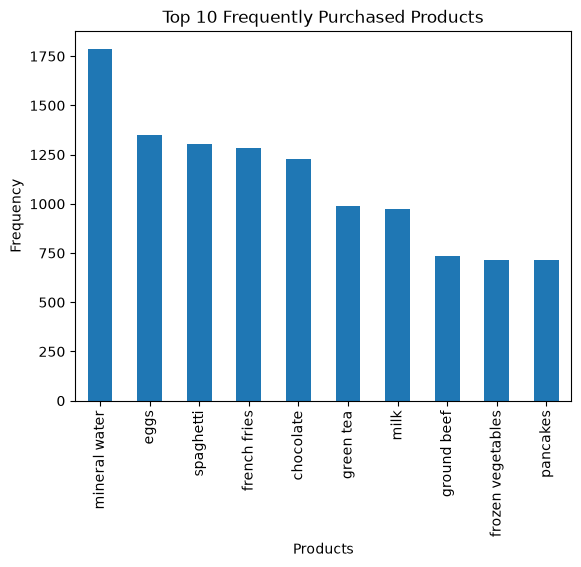

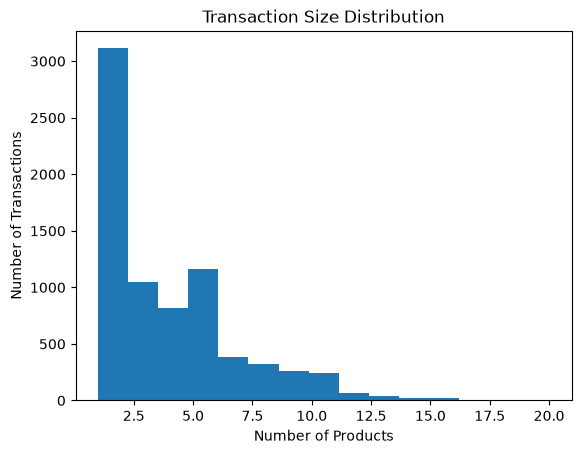

In [13]:

import matplotlib.pyplot as plt

# 1. Top 10 product frequencies
p.value_counts().head(10).plot(kind="bar")

plt.title("Top 10 Frequently Purchased Products")
plt.xlabel("Products")
plt.ylabel("Frequency")
plt.show()

# 2. Transaction-size distribution
k.plot(kind="hist", bins=15)

plt.title("Transaction Size Distribution")
plt.xlabel("Number of Products")
plt.ylabel("Number of Transactions")
plt.show()


## 8. Transaction Encoding Using MultiLabelBinarizer

Each shopping basket is converted into a binary feature vector using MultiLabelBinarizer. Each column represents a unique product. A value of 1 indicates that the product is present in the transaction, while 0 indicates that it is absent.

The resulting numerical matrix can be used by machine learning algorithms to analyze similarities between transactions.

In [14]:
from sklearn.preprocessing import MultiLabelBinarizer

transactions = df.apply(
    lambda row: row.dropna().tolist(), axis=1
).tolist()

mlb = MultiLabelBinarizer()
X = mlb.fit_transform(transactions)

print("Feature matrix shape:", X.shape)
print("Unique products:", len(mlb.classes_))
print("Sample of encoded data:\n", X[:5])
print(mlb.classes_)


Feature matrix shape: (7501, 119)
Unique products: 119
Sample of encoded data:
 [[1 1 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0
  0 0 1 0 0 0 0 0 0 0 0 1 0 0 0 0 1 1 0 0 0 0 0 1 0 0 0 0 1 0 0 0 0 0 0 1
  0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 1 0 0 0 0 1 0 0 0 1 0 0
  0 0 1 0 0 1 0 0 1 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0

## 9. Principal Component Analysis (PCA)

PCA reduces the high-dimensional transaction feature matrix to two principal components. These components are used to visualize the transactions in a two-dimensional scatter plot and provide input for the clustering algorithms in this implementation.

**Interpretation:** The scatter plot shows the distribution of transactions in the reduced feature space. Overlapping points may indicate similar representations, but the plot alone does not establish the quality of the clusters.

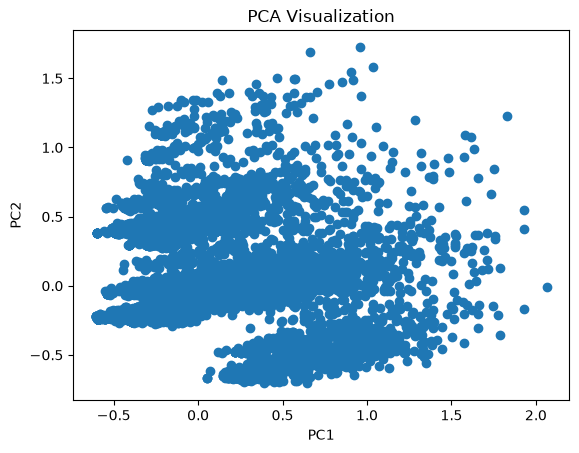

(7501, 2)

In [15]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Apply PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

# Visualize the data
plt.scatter(X_pca[:, 0], X_pca[:, 1])
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA Visualization")
plt.show()
X_pca.shape

## 10. K-means Clustering

K-means partitions the transactions into three clusters based on their distances from cluster centroids in the two-dimensional PCA space. The algorithm assigns each transaction to a cluster to minimize within-cluster variation.

In [16]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_pca )

print("Training clusters:", kmeans_labels)

Training clusters: [0 2 1 ... 1 1 2]


## 11. Hierarchical Clustering

Agglomerative Hierarchical Clustering starts with individual transactions and progressively merges similar transactions into larger groups. In this implementation, the algorithm produces three clusters using the two PCA components.

In [17]:
from sklearn.cluster import AgglomerativeClustering

hc = AgglomerativeClustering(n_clusters=3)
hc_labels = hc.fit_predict(X_pca )

print(hc_labels)

[0 1 2 ... 2 2 1]


## 12. Spectral Clustering

Spectral Clustering uses relationships between nearby data points to identify groups that may not be easily separated by simple geometric boundaries. The implementation uses a nearest-neighbor affinity graph and requests three clusters.

In [18]:
from sklearn.cluster import SpectralClustering,DBSCAN

sc = SpectralClustering(
    n_clusters=3,
    random_state=42,
    affinity="nearest_neighbors",
    n_neighbors=23
)

sc_labels = sc.fit_predict(X_pca )

print(sc_labels)

[2 0 1 ... 1 0 0]


## 13. DBSCAN Clustering

DBSCAN groups points based on their density in the PCA space. It identifies dense regions as clusters and may label isolated points as noise. Unlike the other algorithms in this study, DBSCAN does not require the number of clusters to be specified in advance.

In [19]:
dbscan = DBSCAN(eps=0.1, min_samples=5)
dbscan_labels = dbscan.fit_predict(X_pca)
print(dbscan_labels)

[0 0 0 ... 0 0 0]


## 14. Evaluation of Clustering Algorithms

The clustering algorithms are compared using the Silhouette Score and Davies–Bouldin Index.

- **Silhouette Score:** Ranges from -1 to +1. Higher values generally indicate better separation between clusters.
- **Davies–Bouldin Index:** Measures cluster similarity based on compactness and separation. Lower values generally indicate better clustering.

The metrics are calculated using the two PCA components and the labels generated by each algorithm. Therefore, the results evaluate clustering in the reduced space rather than the original 119-dimensional feature space. For DBSCAN, noise points and cases with an invalid number of clusters must be handled appropriately before interpreting the metrics.

In [20]:
from sklearn.metrics import silhouette_score, davies_bouldin_score

# K-means
print("K-means:")
print("Silhouette Score:", silhouette_score(X_pca , kmeans_labels))
print("Davies-Bouldin Index:", davies_bouldin_score(X_pca , kmeans_labels))

# Hierarchical Clustering
print("\nHierarchical Clustering:")
print("Silhouette Score:", silhouette_score(X_pca , hc_labels))
print("Davies-Bouldin Index:", davies_bouldin_score(X_pca , hc_labels))

# Spectral Clustering
print("\nSpectral Clustering:")
print("Silhouette Score:", silhouette_score(X_pca , sc_labels))
print("Davies-Bouldin Index:", davies_bouldin_score(X_pca , sc_labels))

# DBSCAN Clustering
print("\nDBSCAN Clustering:")
print("Silhouette Score:", silhouette_score(X_pca , dbscan_labels))
print("Davies-Bouldin Index:", davies_bouldin_score(X_pca , dbscan_labels))


K-means:
Silhouette Score: 0.4863114224146859
Davies-Bouldin Index: 0.7792166308588454

Hierarchical Clustering:
Silhouette Score: 0.4831224324509761
Davies-Bouldin Index: 0.7760423071229612

Spectral Clustering:
Silhouette Score: 0.2340041733965032
Davies-Bouldin Index: 0.8769632497658253

DBSCAN Clustering:
Silhouette Score: 0.3771134383981005
Davies-Bouldin Index: 1.62893454368595


## 15. Limitations

1. **Information Loss:** Reducing 119 product features to two PCA components may remove useful information.
2. **Parameter Dependence:** Results depend on the selected clustering algorithm and its parameters.
3. **Duplicate Transactions:** Retained duplicate baskets may influence the clustering results.
4. **Limited Dataset Information:** The dataset does not explain why customers purchase particular products.
5. **Evaluation Limitations:** Metrics calculated in the two-dimensional PCA space may not fully represent clustering quality in the original feature space.

## 16. Conclusion

This case study applies data cleaning, descriptive statistics, visualization, binary transaction encoding, PCA, and four clustering algorithms to analyze online retail shopping baskets. The Silhouette Score and Davies–Bouldin Index provide complementary ways to compare the resulting clusters. The findings can help explore transaction similarities, although additional validation in the original feature space would provide a more complete assessment.